# Redstart Canteen — Sales & Inventory Analysis

**Python reproduction of the original Excel analysis** (BDM Capstone Project, IIT Madras BS in Data Science).

The original analysis was done in Excel (pivot tables, Pareto charts, inventory ratios). This notebook reproduces the same analyses in Python from the same data.

> The raw data belongs to the store and is kept private, so this notebook is published with its outputs.

**Data:** daily sales records of a campus grocery store (19 Feb – 26 Apr 2024, weeks 8–17) and bi-weekly inventory records.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
IMG = "../images/"
NAVY, TEAL, GREY = "#1f3a5f", "#2a9d8f", "#9aa5b1"


## 1. Load data

In [2]:
sales = pd.read_csv("../data/sales_data.csv", parse_dates=["DATE"])
inventory = pd.read_csv("../data/inventory_data.csv")
print(sales.shape, inventory.shape)
print("Sales columns:", list(sales.columns))
print("Inventory columns:", list(inventory.columns))

(4961, 13) (1706, 6)
Sales columns: ['DATE', 'PRODUCT NAME', 'PRODUCT ID', 'BRAND', 'SUB CATEGORY', 'QUANTITY SOLD', 'MRP', 'COST PRICE', 'REVENUE', 'PROFIT', 'WEEK NUMBER', 'DAY', 'PAYMENT METHOD']
Inventory columns: ['Product', 'Opening Stock', 'Sales', 'Inward Stock', 'Closing Stock', 'Weeks']


In [3]:
# Sanity checks: revenue = quantity x MRP, profit = (MRP - cost price) x quantity
assert (sales["REVENUE"] == sales["QUANTITY SOLD"] * sales["MRP"]).all()
assert (sales["PROFIT"] == (sales["MRP"] - sales["COST PRICE"]) * sales["QUANTITY SOLD"]).all()
print("Date range:", sales["DATE"].min().date(), "to", sales["DATE"].max().date())
print("Product IDs:", sales["PRODUCT ID"].nunique(), "| distinct product names:", sales["PRODUCT NAME"].nunique(),
      "| sub-categories:", sales["SUB CATEGORY"].nunique())

Date range: 2024-02-19 to 2024-04-26
Product IDs: 632 | distinct product names: 2274 | sub-categories: 91


Each `PRODUCT ID` corresponds to one brand and can cover several product names (e.g. different pack sizes or loose items).
All product-level analysis below is at the `PRODUCT ID` level, as in the original workbook. Each row is one product's total sales for one day; quantity is in pieces for packaged goods and kg for loose items.

## 2. Headline numbers

In [4]:
# Absolute revenue and profit are not printed: they are the store's confidential figures.
print(f"Trading days  : {sales['DATE'].nunique()}")
print(f"Quantity sold : {sales['QUANTITY SOLD'].sum():,} (units for packaged goods, kg for loose items)")
print(f"Profit margin : {sales['PROFIT'].sum() / sales['REVENUE'].sum():.1%} of revenue")

Trading days  : 68
Quantity sold : 46,241 (units for packaged goods, kg for loose items)
Profit margin : 13.3% of revenue


In [5]:
pay = sales.groupby("PAYMENT METHOD")[["QUANTITY SOLD", "REVENUE"]].sum()
(pay / pay.sum()).round(4)

,QUANTITY SOLD,REVENUE
PAYMENT METHOD,,
Cash,0.045,0.0548
UPI,0.955,0.9452


## 3. Pareto analysis — sales volume and revenue

In [6]:
def pareto(series):
    s = series.sort_values(ascending=False)
    cum = s.cumsum() / s.sum()
    n80 = int((cum < 0.8).sum()) + 1
    top20 = s.head(int(len(s) * 0.2)).sum() / s.sum()
    return s, cum, n80, top20

vol, vol_cum, vol_n80, vol_top20 = pareto(sales.groupby("PRODUCT ID")["QUANTITY SOLD"].sum())
rev, rev_cum, rev_n80, rev_top20 = pareto(sales.groupby("PRODUCT ID")["REVENUE"].sum())
n = len(vol)
print(f"Volume : {vol_n80} of {n} product IDs ({vol_n80/n:.1%}) make up 80% of quantity; top 20% = {vol_top20:.1%} of quantity")
print(f"Revenue: {rev_n80} of {n} product IDs ({rev_n80/n:.1%}) make up 80% of revenue; top 20% = {rev_top20:.1%} of revenue")

Volume : 78 of 632 product IDs (12.3%) make up 80% of quantity; top 20% = 87.6% of quantity
Revenue: 86 of 632 product IDs (13.6%) make up 80% of revenue; top 20% = 85.7% of revenue


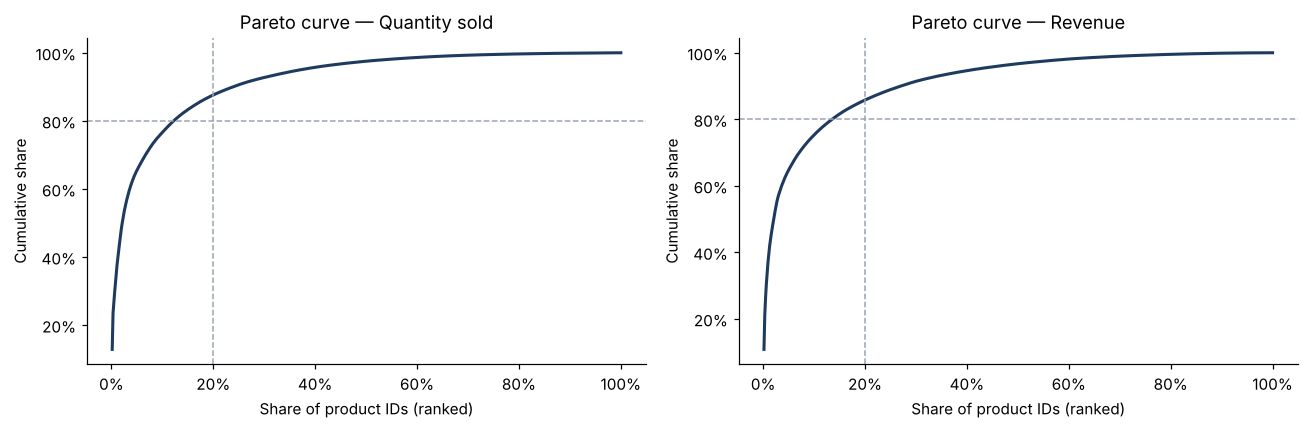

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cum, n80, title in [(axes[0], vol_cum, vol_n80, "Quantity sold"), (axes[1], rev_cum, rev_n80, "Revenue")]:
    x = np.arange(1, len(cum) + 1) / len(cum)
    ax.plot(x, cum.values, color=NAVY, lw=2)
    ax.axhline(0.8, color=GREY, ls="--", lw=1)
    ax.axvline(0.2, color=GREY, ls="--", lw=1)
    ax.set_title(f"Pareto curve — {title}")
    ax.set_xlabel("Share of product IDs (ranked)")
    ax.set_ylabel("Cumulative share")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout(); plt.savefig(IMG + "pareto.png", bbox_inches="tight"); plt.show()

In [8]:
brand = sales.groupby("PRODUCT ID")["BRAND"].first().astype(str)
top_rev = pd.DataFrame({"Brand": brand[rev.head(10).index], "Share of revenue": (rev.head(10) / rev.sum()).round(4)})
top_rev

,Brand,Share of revenue
PRODUCT ID,,
PID_22,LOOSE,0.1080
PID_30,Loose,0.1031
PID_23,Fortune,0.0532
PID_116,Best Choice,0.0419
PID_15,Emami,0.0326
PID_14,Ganesh,0.0315
PID_136,Remote,0.0249
PID_33,Sunway,0.0233
PID_11,Jk,0.0185


## 4. Weekly sales trend

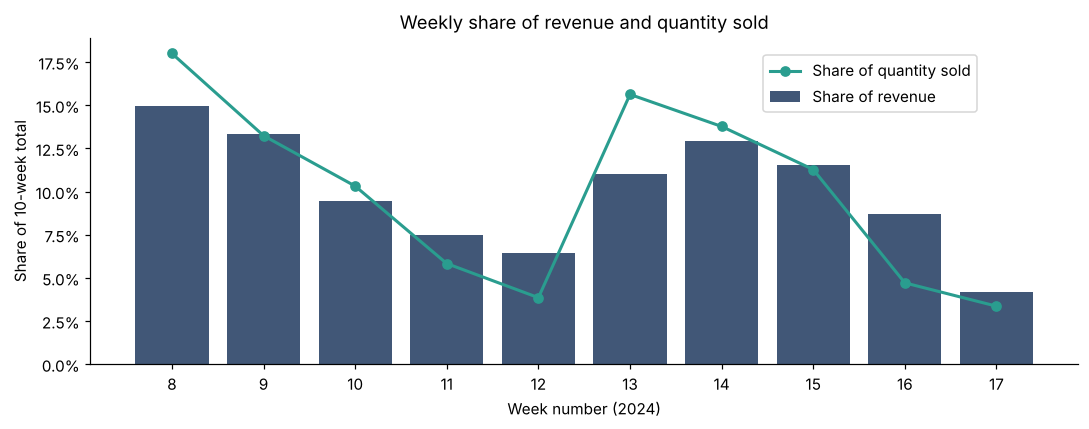

,Share of revenue,Share of quantity
WEEK NUMBER,,
8,0.149,0.180
9,0.133,0.132
10,0.094,0.103
11,0.075,0.058
12,0.064,0.039
13,0.110,0.156
14,0.129,0.138
15,0.115,0.113
16,0.087,0.047


In [9]:
weekly = sales.groupby("WEEK NUMBER")[["REVENUE", "QUANTITY SOLD"]].sum()
weekly = (weekly / weekly.sum()).rename(columns={"REVENUE": "Share of revenue", "QUANTITY SOLD": "Share of quantity"})
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(weekly.index, weekly["Share of revenue"], color=NAVY, alpha=0.85, label="Share of revenue")
ax1.plot(weekly.index, weekly["Share of quantity"], color=TEAL, marker="o", lw=2, label="Share of quantity sold")
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax1.set_xlabel("Week number (2024)"); ax1.set_ylabel("Share of 10-week total")
ax1.set_xticks(weekly.index)
ax1.set_title("Weekly share of revenue and quantity sold")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.tight_layout(); plt.savefig(IMG + "weekly_trend.png", bbox_inches="tight"); plt.show()
weekly.round(3)

## 5. Revenue vs. volume segmentation

In [10]:
seg = sales.groupby("PRODUCT ID")[["QUANTITY SOLD", "REVENUE"]].sum()
q_med, r_med = seg["QUANTITY SOLD"].median(), seg["REVENUE"].median()
seg["Segment"] = np.select(
    [(seg["QUANTITY SOLD"] >= q_med) & (seg["REVENUE"] >= r_med),
     (seg["QUANTITY SOLD"] >= q_med) & (seg["REVENUE"] < r_med),
     (seg["QUANTITY SOLD"] < q_med) & (seg["REVENUE"] >= r_med)],
    ["High volume - High revenue", "High volume - Low revenue", "Low volume - High revenue"],
    default="Low volume - Low revenue")
seg["Segment"].value_counts()

Segment
High volume - High revenue    249
Low volume - Low revenue      241
High volume - Low revenue      75
Low volume - High revenue      67
Name: count, dtype: int64

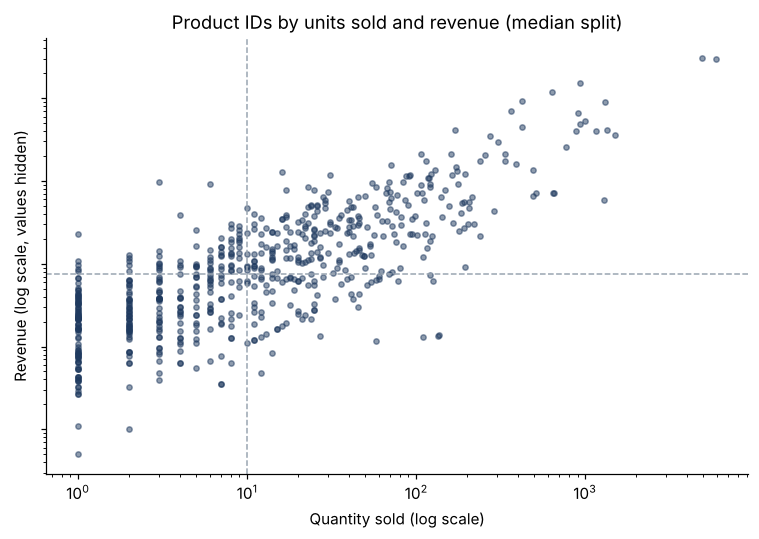

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(seg["QUANTITY SOLD"], seg["REVENUE"], s=12, color=NAVY, alpha=0.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(q_med, color=GREY, ls="--", lw=1); ax.axhline(r_med, color=GREY, ls="--", lw=1)
ax.set_xlabel("Quantity sold (log scale)"); ax.set_ylabel("Revenue (log scale, values hidden)"); ax.set_yticklabels([])
ax.set_title("Product IDs by units sold and revenue (median split)")
plt.tight_layout(); plt.savefig(IMG + "revenue_vs_volume.png", bbox_inches="tight"); plt.show()

## 6. Profit contribution

In [12]:
profit = sales.groupby("PRODUCT ID")["PROFIT"].sum().sort_values(ascending=False)
share = profit / profit.sum()
top_profit = pd.DataFrame({"Brand": brand[share.head(10).index], "Share of profit": share.head(10).round(4)})
top_profit

,Brand,Share of profit
PRODUCT ID,,
PID_22,LOOSE,0.1022
PID_116,Best Choice,0.0935
PID_30,Loose,0.0911
PID_23,Fortune,0.0618
PID_15,Emami,0.0545
PID_136,Remote,0.0525
PID_14,Ganesh,0.0361
PID_33,Sunway,0.0316
PID_56,Cookme,0.0255


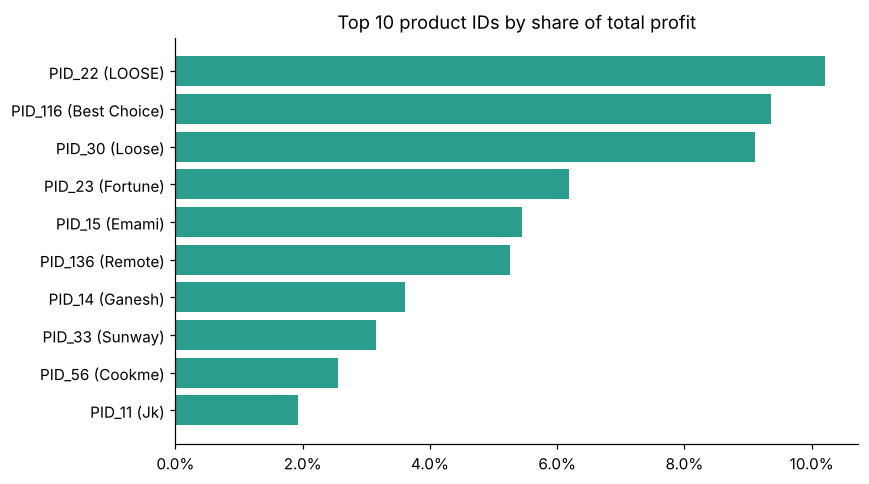

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{pid} ({brand[pid]})" for pid in share.head(10).index][::-1]
ax.barh(labels, share.head(10).values[::-1], color=TEAL)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Top 10 product IDs by share of total profit")
plt.tight_layout(); plt.savefig(IMG + "profit_share.png", bbox_inches="tight"); plt.show()

## 7. Inventory ratio — understocked vs. overstocked products

Inventory ratio = average opening stock / average sales across the bi-weekly periods (as in the original workbook).
A **very low ratio** means stock on hand is small relative to demand (stock-out risk); a **very high ratio** means stock sits unsold (overstocking).

> **Note:** In the shared workbook, opening and closing stock for weeks 14 & 15 come from a lookup to an external file and show as errors, so they are missing here. Averages below use the remaining periods, so values can differ slightly from the original pivot table.

In [14]:
inventory.groupby("Weeks")["Opening Stock"].apply(lambda s: s.isna().sum())

Weeks
10 & 11      0
12 & 13      0
14 & 15    322
16 & 17      0
8 & 9        0
Name: Opening Stock, dtype: int64

In [15]:
ratio = inventory.groupby("Product").agg(avg_opening=("Opening Stock", "mean"), avg_sales=("Sales", "mean"))
ratio = ratio[ratio["avg_sales"] > 0].dropna()
ratio["inventory_ratio"] = ratio["avg_opening"] / ratio["avg_sales"]
ratio["Brand"] = brand.reindex(ratio.index)
print("Lowest ratios (stock-out risk):")
display(ratio.sort_values("inventory_ratio").head(10).round(3))
print("Highest ratios (overstocked):")
display(ratio.sort_values("inventory_ratio", ascending=False).head(10).round(3))

Lowest ratios (stock-out risk):


,avg_opening,avg_sales,inventory_ratio,Brand
Product,,,,
PID_160,1.000,274.20,0.004,WHISPER CHOICE
PID_451,2.000,509.00,0.004,HORLICKS
PID_558,9.000,1717.50,0.005,MAMY POKO
PID_273,2.667,506.25,0.005,ANARAS
PID_497,2.000,287.50,0.007,good vibes
PID_136,34.250,3983.80,0.009,Remote
PID_15,63.250,6380.20,0.010,Emami
PID_173,3.500,344.50,0.010,manna
PID_23,86.000,7569.00,0.011,Fortune


Highest ratios (overstocked):


,avg_opening,avg_sales,inventory_ratio,Brand
Product,,,,
PID_397,29.000,1.00,29.000,YOGA BAR
PID_247,47.333,1.75,27.048,Tresemme
PID_575,23.000,1.00,23.000,HIMALAYAN NATIVES
PID_517,8.500,0.50,17.000,MUSCLEBLAZE
PID_462,147.000,9.50,15.474,LAYS
PID_494,14.000,1.00,14.000,Bakery
PID_481,27.000,2.00,13.500,PRIYAGOLD
PID_585,13.000,1.00,13.000,DENVER
PID_581,12.000,1.00,12.000,maggi


## 8. Summary

In [16]:
print(f"{sales['DATE'].nunique()} trading days over {sales['WEEK NUMBER'].nunique()} weeks; profit margin {sales['PROFIT'].sum()/sales['REVENUE'].sum():.1%}")
print(f"{vol_n80/n:.0%} of product IDs drive 80% of quantity; {rev_n80/n:.0%} drive 80% of revenue")
print(f"Top 3 product IDs by profit contribute {share.head(3).sum():.1%} of total profit")
print(f"UPI share of quantity sold: {pay.loc['UPI','QUANTITY SOLD']/pay['QUANTITY SOLD'].sum():.1%}")

68 trading days over 10 weeks; profit margin 13.3%
12% of product IDs drive 80% of quantity; 14% drive 80% of revenue
Top 3 product IDs by profit contribute 28.7% of total profit
UPI share of quantity sold: 95.5%
